In [1]:
import pickle
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
data_dict = pickle.load(open('./datas/data_v1.pickle', 'rb'))
data = np.asarray(data_dict['data'], dtype=np.float32)
labels = np.asarray(data_dict['labels'], dtype=np.float32)

# 3. Split dataset - 80 10 10
x_train, x_temp, y_train, y_temp = train_test_split(
    data,
    labels,
    test_size=0.2,
    random_state=42
)

x_test, x_val, y_test, y_val = train_test_split(
    x_temp,
    y_temp,
    test_size=0.5,
    random_state=42
)

model = Sequential([
    Dense(128, activation='relu', input_shape=(data.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(len(np.unique(labels)), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(x_val,y_val)
)

y_probability = model.predict(x_test)
y_predict = np.argmax(y_probability, axis=1)

score = accuracy_score(y_test, y_predict)
print('{}% of samples were classified correctly !'.format(
    score * 100
))

c:\Users\richi\OneDrive\Desktop\Richie\Deep and Machine Learning\AOL_DeepLearning_ASL\env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.1639 - loss: 3.0212 - val_accuracy: 0.2385 - val_loss: 2.7347
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3048 - loss: 2.3964 - val_accuracy: 0.5885 - val_loss: 2.0092
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4688 - loss: 1.7959 - val_accuracy: 0.8308 - val_loss: 1.4912
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6178 - loss: 1.3853 - val_accuracy: 0.8038 - val_loss: 1.1231
Epoch 5/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7433 - loss: 1.0463 - val_accuracy: 0.8654 - val_loss: 0.8248
Epoch 6/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8144 - loss: 0.8019 - val_accuracy: 0.8923 - val_loss: 0.6292
Epoch 7/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8524 - loss: 0.6303 - val_accuracy: 0.8923 - val_loss: 0.4976
Epoch 8/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8918 - loss: 0.5037 - val_accuracy: 0.9308 - val_loss:

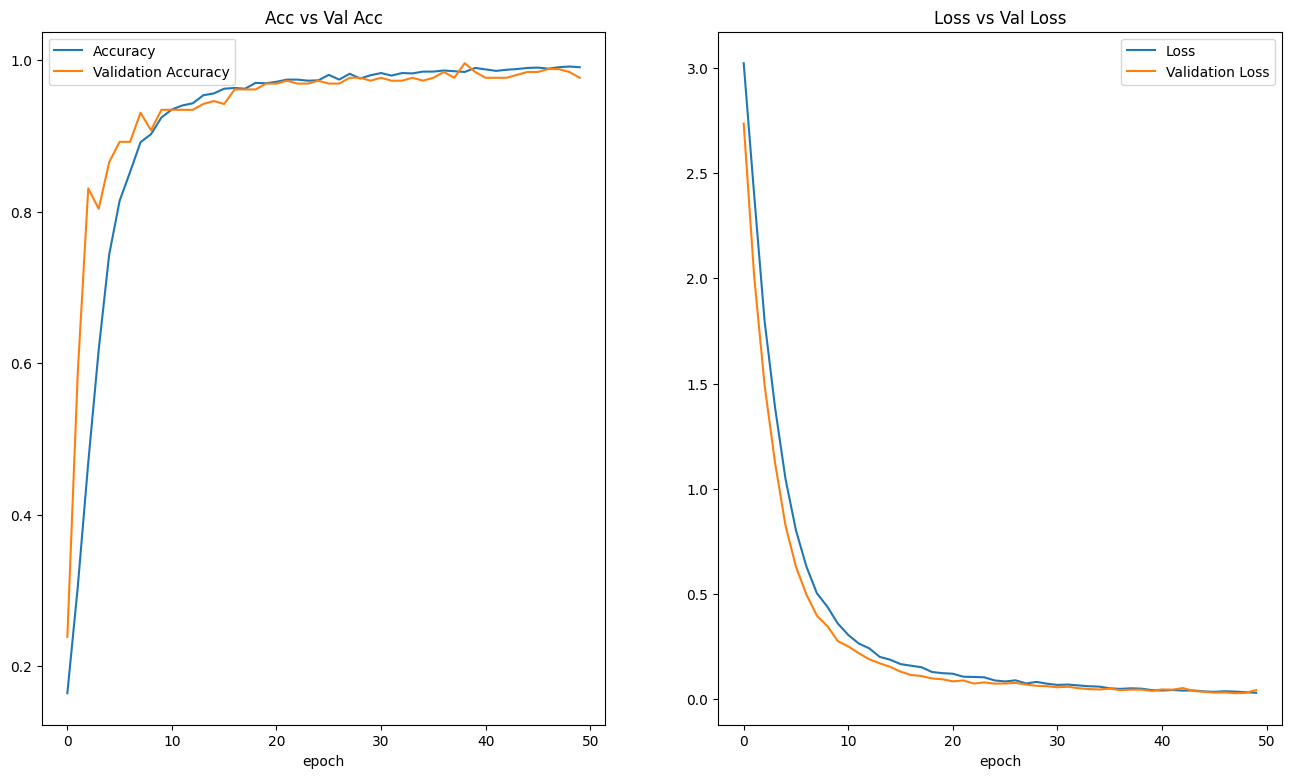

In [3]:
plt.figure(figsize=(16,9))
plt.subplot(1,2,1)
plt.title('Acc vs Val Acc')
plt.xlabel('epoch')
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.title('Loss vs Val Loss')
plt.xlabel('epoch')
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()

plt.show()

In [4]:
MODEL_DIR='./model'

version = 1
while os.path.exists(f'./model/v{version}'):
    version += 1

DATA_DIR = f'./{MODEL_DIR}/v{version}/'
os.makedirs(DATA_DIR, exist_ok=True)

model.save(f'{MODEL_DIR}/v{version}/hand_gesture_model.keras')
with open(f'{MODEL_DIR}/v{version}/labels.pickle', 'wb') as f:
    pickle.dump(labels, f)